#Freshmart Case Study

#Transactions EDA

#Data Ingestion

In [0]:
transactions= spark.read.table("freshmart.dataset.transactions")

In [0]:
import pandas as pd
import numpy as np

tnx = transactions.toPandas()

display(tnx)

transaction_id,store_id,transaction_date,day_of_week,customer_id,is_loyalty_member,num_items,basket_value_zar,payment_method
TX0000001,ST1001,2025-01-01,Wednesday,null,No,25,487.08000000000000,Card
TX0000002,ST1001,2025-01-01,Wednesday,C889732,Yes,32,537.29000000000000,Cash
TX0000003,ST1001,2025-01-01,Wednesday,null,No,19,412.58000000000000,Cash
TX0000004,ST1001,2025-01-01,Wednesday,C955607,Yes,24,589.55000000000000,Card
TX0000005,ST1001,2025-01-01,Wednesday,C867011,Yes,1,19.98000000000000,Cash
TX0000006,ST1001,2025-01-01,Wednesday,null,No,20,333.32000000000000,Cash
TX0000007,ST1001,2025-01-01,Wednesday,C392524,Yes,27,406.10000000000000,Card
TX0000008,ST1001,2025-01-01,Wednesday,C873016,Yes,20,354.67000000000000,Cash
TX0000009,ST1001,2025-01-01,Wednesday,null,No,3,77.27000000000000,Cash
TX0000010,ST1002,2025-01-01,Wednesday,C944088,Yes,13,261.71000000000000,Mobile


In [0]:
tnx.shape        #size of tabel- 64330 rows, 9 columns

(64330, 9)

In [0]:
tnx.info()      #Notice how every column is in text format except the number of items. We need to convert the data types of some columns to successfully complete the EDA.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64330 entries, 0 to 64329
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   transaction_id     64330 non-null  object
 1   store_id           64330 non-null  object
 2   transaction_date   64330 non-null  object
 3   day_of_week        64330 non-null  object
 4   customer_id        28656 non-null  object
 5   is_loyalty_member  64330 non-null  object
 6   num_items          64330 non-null  int64 
 7   basket_value_zar   64330 non-null  object
 8   payment_method     64330 non-null  object
dtypes: int64(1), object(8)
memory usage: 4.4+ MB


Since most  of the values above are stored in a text format, I am limited in using math, date filtering or any logical checks. I need to convert the data. 

In [0]:
#Data Conversion

import pandas as pd

# 1. Clean and convert financial column to decimal (removes currency symbols if any exist)
tnx['basket_value_zar'] = pd.to_numeric(tnx['basket_value_zar'].astype(str).str.replace(r'[^\d.]', '', regex=True))

# 2. Convert date column to actual datetime objects
tnx['transaction_date'] = pd.to_datetime(tnx['transaction_date'])

# 3. Convert loyalty status to boolean (assumes data is 'True'/'False' or 1/0 strings)
# If it uses 'Yes'/'No', use: tnx['is_loyalty_member'].map({'Yes': True, 'No': False})
#tnx['is_loyalty_member'] = tnx['is_loyalty_member'].astype(bool)

# 4. Convert repetitive text columns to categories to save memory
category_cols = ['store_id', 'day_of_week', 'payment_method']
tnx[category_cols] = tnx[category_cols].astype('category')

# Verify the changes
tnx.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64330 entries, 0 to 64329
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   transaction_id     64330 non-null  object        
 1   store_id           64330 non-null  category      
 2   transaction_date   64330 non-null  datetime64[ns]
 3   day_of_week        64330 non-null  category      
 4   customer_id        28656 non-null  object        
 5   is_loyalty_member  64330 non-null  object        
 6   num_items          64330 non-null  int64         
 7   basket_value_zar   64330 non-null  float64       
 8   payment_method     64330 non-null  category      
dtypes: category(3), datetime64[ns](1), float64(1), int64(1), object(3)
memory usage: 3.1+ MB


In [0]:
tnx.isnull().sum()       #check the sum of null values in each column
                         # blank or "null" customer_id means that client is not a loyal member. It will remain as "NULL"

transaction_id           0
store_id                 0
transaction_date         0
day_of_week              0
customer_id          35674
is_loyalty_member        0
num_items                0
basket_value_zar         0
payment_method           0
dtype: int64

From above code, we classified that we cannot use the "customer_id" column because it is a unique identifier.
Another observation is that clients without the Customer_id are not loyal members. It is a flag. They do not have loyaly cards.

In [0]:
tnx.duplicated().sum()      #I want to count the total duplicates in the table

np.int64(0)

In [0]:
#Unique payment method types

tnx["payment_method"].value_counts()

payment_method
Card      32306
Cash      19754
Mobile    12270
Name: count, dtype: int64

In [0]:
# I want to compre which store performs the best by total num_items sold, and total baskey_value_zar


# # 1. Ensure basket_value_zar is a number (if you haven't converted it yet)
#tnx['basket_value_zar'] = pd.to_numeric(tnx['basket_value_zar'].astype(str).str.replace(r'[^\d.]', '', regex=True))

# 2. Group by store and sum the totals
store_comparison = tnx.groupby('store_id').agg(
    total_quantity=('num_items', 'sum'),
    total_basket_value=('basket_value_zar', 'sum')
).reset_index().sort_values(by='store_id', ascending=False)

# 3. View the result
print(store_comparison)


   store_id  total_quantity  total_basket_value
41   ST1042           18363           373958.30
40   ST1041           18772           385477.14
39   ST1040           19192           393234.81
38   ST1039           11151           227546.79
37   ST1038           18537           376736.99
36   ST1037           10460           215476.95
35   ST1036           19781           406390.73
34   ST1035            9800           202394.58
33   ST1034           10823           220278.01
32   ST1033           10273           210269.13
31   ST1032           20345           417738.74
30   ST1031           17674           355518.54
29   ST1030           31139           637556.04
28   ST1029           31005           631721.26
27   ST1028           18686           379485.30
26   ST1027           31025           630287.47
25   ST1026           18932           387866.71
24   ST1025           29828           606372.53
23   ST1024           29689           603089.05
22   ST1023           18744           38

/home/spark-ed65d314-9e4f-48c2-a045-4d/.ipykernel/305/command-6890469962953506-3815470810:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  store_comparison = tnx.groupby('store_id').agg(


In [0]:
#I want to compare the day_of_week which is most popular to clients/ or the busiest in terms of sales.


# 1. Ensure basket_value_zar is numerical
#tnx['basket_value_zar'] = pd.to_numeric(tnx['basket_value_zar'].astype(str).str.replace(r'[^\d.]', '', regex=True))

# 2. Group by day of week and calculate metrics
day_comparison = tnx.groupby('day_of_week').agg(
    customer_count_inc_null=('customer_id', 'size'),    # 'size' counts every row, including nulls
    total_items=('num_items', 'sum'),
    total_basket_value=('basket_value_zar', 'sum')
).reset_index()

# 3. Sort by total basket value in descending order to see the highest sales day first
day_comparison = day_comparison.sort_values(by='total_basket_value', ascending=False)

# 4. View the result
print(day_comparison)


  day_of_week  customer_count_inc_null  total_items  total_basket_value
3      Sunday                    11756       158879          3250784.37
2    Saturday                    11743       157649          3226045.55
6   Wednesday                     8418       113732          2328587.07
1      Monday                     8235       109514          2243165.67
5     Tuesday                     8140       109852          2242156.02
0      Friday                     8195       109806          2241020.15
4    Thursday                     7843       105683          2164355.17


/home/spark-ed65d314-9e4f-48c2-a045-4d/.ipykernel/305/command-6890469962953507-394390875:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  day_comparison = tnx.groupby('day_of_week').agg(


In [0]:
# I want to compare the loyalty status of customers who bring the most revenue


# 1. Ensure basket_value_zar is numerical
#tnx['basket_value_zar'] = pd.to_numeric(tnx['basket_value_zar'].astype(str).str.replace(r'[^\d.]', '', regex=True))

# 2. Group by loyalty status and calculate total revenue and transaction counts
loyalty_comparison = tnx.groupby('is_loyalty_member').agg(
    total_revenue=('basket_value_zar', 'sum'),
    total_transactions=('basket_value_zar', 'count'),
    average_spend=('basket_value_zar', 'mean')
).reset_index()

# 3. Sort by total revenue in descending order
loyalty_comparison = loyalty_comparison.sort_values(by='total_revenue', ascending=False)

# 4. View the result
print(loyalty_comparison)


  is_loyalty_member  total_revenue  total_transactions  average_spend
0                No      9267823.8               35674     259.792112
1               Yes      8428290.2               28656     294.119563


#Stores EDA


#Data Ingestion

In [0]:
stores= spark.read.table("freshmart.dataset.stores")

In [0]:
import pandas as pd
import numpy as np

strs= stores.toPandas()
display(strs)

store_id,store_name,province,store_format,floor_area_sqm,opened_year,region_manager,has_nearby_competitor,competitor_open_date
ST1001,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null
ST1002,FreshMart Pretoria 3,Gauteng,Express,422,2010,T. Molefe,No,null
ST1003,FreshMart Soweto 4,Gauteng,Express,671,2013,R. Petersen,No,null
ST1004,FreshMart Pretoria 6,Gauteng,Large,3526,2017,R. Petersen,Yes,2025-09-25
ST1005,FreshMart Benoni 8,Gauteng,Express,653,2015,P. van Wyk,No,null
ST1006,FreshMart Benoni 5,Gauteng,Large,3245,2016,T. Molefe,No,null
ST1007,FreshMart Pretoria 8,Gauteng,Large,2822,2009,N. Dlamini,No,null
ST1008,FreshMart Randburg 5,Gauteng,Medium,2020,2006,R. Petersen,Yes,2025-08-20
ST1009,FreshMart Soweto 8,Gauteng,Medium,1438,2014,P. van Wyk,No,null
ST1010,FreshMart Randburg 1,Gauteng,Medium,2150,2020,R. Petersen,No,null


In [0]:
strs.shape      #table has 42 rows and 9 columns

(42, 9)

In [0]:
strs.isnull().sum() 

store_id                  0
store_name                0
province                  0
store_format              0
floor_area_sqm            0
opened_year               0
region_manager            0
has_nearby_competitor     0
competitor_open_date     30
dtype: int64

In [0]:
strs.info()         #I wanna check the data types per column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   store_id               42 non-null     object
 1   store_name             42 non-null     object
 2   province               42 non-null     object
 3   store_format           42 non-null     object
 4   floor_area_sqm         42 non-null     int64 
 5   opened_year            42 non-null     int64 
 6   region_manager         42 non-null     object
 7   has_nearby_competitor  42 non-null     object
 8   competitor_open_date   12 non-null     object
dtypes: int64(2), object(7)
memory usage: 3.1+ KB


In [0]:
# Group by store format and province, then count unique store IDs
store_counts = strs.groupby(['store_format', 'province']).agg(
    total_stores=('store_id', 'nunique')
).reset_index()

# View the result
display(store_counts)


store_format,province,total_stores
Express,Gauteng,3
Express,KwaZulu-Natal,5
Express,Western Cape,2
Large,Gauteng,9
Large,Western Cape,5
Medium,Gauteng,6
Medium,KwaZulu-Natal,6
Medium,Western Cape,6


In [0]:
#How many stores have near by competitors

# Direct breakdown of store counts
print(strs['has_nearby_competitor'].value_counts())


has_nearby_competitor
No     30
Yes    12
Name: count, dtype: int64


#Stockouts EDA

#Data Ingestion

In [0]:
stockouts= spark.read.table("freshmart.dataset.stockouts")

In [0]:
import pandas as pd
import numpy as np

stock= stockouts.toPandas()
display(stock) 

stockout_id,store_id,date,category,duration_hours,note
SO0020,ST1039,2025-09-06,Household Cleaning,9,Replenishment gap - weekend delivery missed
SO0104,ST1040,2025-09-06,Household Cleaning,6,Replenishment gap - weekend delivery missed
SO0082,ST1006,2025-09-07,Household Cleaning,9,Replenishment gap - weekend delivery missed
SO0001,ST1024,2025-09-07,Household Cleaning,7,Replenishment gap - weekend delivery missed
SO0021,ST1039,2025-09-07,Household Cleaning,10,Replenishment gap - weekend delivery missed
SO0105,ST1040,2025-09-07,Household Cleaning,9,Replenishment gap - weekend delivery missed
SO0065,ST1041,2025-09-07,Household Cleaning,7,Replenishment gap - weekend delivery missed
SO0041,ST1002,2025-09-13,Household Cleaning,10,Replenishment gap - weekend delivery missed
SO0106,ST1040,2025-09-13,Household Cleaning,6,Replenishment gap - weekend delivery missed
SO0066,ST1041,2025-09-13,Household Cleaning,9,Replenishment gap - weekend delivery missed


In [0]:
stock.shape

(119, 6)

In [0]:
# Unique categories

print(stock['category'].value_counts())

category
Household Cleaning    119
Name: count, dtype: int64


In [0]:
stock.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   stockout_id     119 non-null    object
 1   store_id        119 non-null    object
 2   date            119 non-null    object
 3   category        119 non-null    object
 4   duration_hours  119 non-null    int64 
 5   note            119 non-null    object
dtypes: int64(1), object(5)
memory usage: 5.7+ KB


In [0]:
import pandas as pd

# 1. Convert the date column to actual datetime objects
stock['date'] = pd.to_datetime(stock['date'])


In [0]:
#I did not convert the category and note data types since there is only one unique value. Category: Household cleaning and for note:"Replenishment gap - weekend delivery missed". 
#Recheck the info

stock.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   stockout_id     119 non-null    object        
 1   store_id        119 non-null    object        
 2   date            119 non-null    datetime64[ns]
 3   category        119 non-null    object        
 4   duration_hours  119 non-null    int64         
 5   note            119 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(4)
memory usage: 5.7+ KB


In [0]:
# See the most frequent causes of stockouts
print(stock['note'].value_counts())


note
Replenishment gap - weekend delivery missed    119
Name: count, dtype: int64


Since every single row in this dataset shares the exact same note ("Replenishment gap - weekend delivery missed"), every stockout incident in this table is a result of a missed weekend delivery.
To find out which stores are experiencing this issue most frequently, I just need to count how many stockout incidents occurred per store_id and sort them from highest to lowest.

In [0]:
# Find the average shelf downtime for each specific issue
cause_severity = stock.groupby('note')['duration_hours'].agg(['count', 'sum', 'mean']).reset_index()
#cause_severity.columns = ['Root Cause', 'Total Incidents', 'Total Hours Lost', 'Avg Hours per Incident']
display(cause_severity)


note,count,sum,mean
Replenishment gap - weekend delivery missed,119,903,7.588235294117647


In [0]:
# Group by store_id and count the total number of missed delivery incidents
store_delivery_failures = stock.groupby('store_id').size().reset_index(name='missed_delivery_count')

# Sort the stores in descending order to see the most frequent offenders at the top
store_delivery_failures = store_delivery_failures.sort_values(by='missed_delivery_count', ascending=False)

# View the full list
print(store_delivery_failures)


  store_id  missed_delivery_count
0   ST1002                     24
1   ST1006                     22
3   ST1039                     21
2   ST1024                     19
5   ST1041                     17
4   ST1040                     16



Taking it a Step Further: Ranking by Total Hours Lost

While counting the number of incidents is helpful, some stores might be left with empty shelves for much longer periods. I can layer in the duration_hours column to see which stores are suffering the most severe operational downtime:

In [0]:
# Calculate both the frequency and the total hours lost per store
store_severity = stock.groupby('store_id').agg(
    incident_count=('stockout_id', 'count'),
    total_hours_empty=('duration_hours', 'sum'),
    avg_hours_per_incident=('duration_hours', 'mean')
).reset_index().sort_values(by='total_hours_empty', ascending=False)

print(store_severity)


  store_id  incident_count  total_hours_empty  avg_hours_per_incident
0   ST1002              24                184                7.666667
3   ST1039              21                173                8.238095
1   ST1006              22                162                7.363636
5   ST1041              17                134                7.882353
2   ST1024              19                129                6.789474
4   ST1040              16                121                7.562500


# Preparing the data before joining

In [0]:
# Import the libraries we need for data preparation and analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create copies so that our original EDA DataFrames remain unchanged
transactions_clean = tnx.copy()
stores_clean = strs.copy()
stockouts_clean = stock.copy()

In [0]:
#Standardise column names and data types

#Why this matters: a date stored as text can cause comparison problems, while a numeric value stored as text cannot be reliably averaged. Consistent store_id formats also prevent failed joins.

# Standardise column names by removing extra spaces and using lowercase
transactions_clean.columns = transactions_clean.columns.str.strip().str.lower()
stores_clean.columns = stores_clean.columns.str.strip().str.lower()
stockouts_clean.columns = stockouts_clean.columns.str.strip().str.lower()

# Convert transaction dates to datetime format
transactions_clean["transaction_date"] = pd.to_datetime(
    transactions_clean["transaction_date"],
    errors="coerce"
)

# Convert the stockout event date to datetime format
stockouts_clean["date"] = pd.to_datetime(
    stockouts_clean["date"],
    errors="coerce"
)

# Convert the competitor opening date to datetime format
stores_clean["competitor_open_date"] = pd.to_datetime(
    stores_clean["competitor_open_date"],
    errors="coerce"
)

# Convert basket value to numeric, preserving negative signs if any exist
# This removes currency symbols and thousands separators if present
transactions_clean["basket_value_zar"] = pd.to_numeric(
    transactions_clean["basket_value_zar"]
        .astype("string")
        .str.replace(r"[^0-9.\-]", "", regex=True),
    errors="coerce"
)

# Convert the number of items into a numeric field
transactions_clean["num_items"] = pd.to_numeric(
    transactions_clean["num_items"],
    errors="coerce"
)

# Convert stockout duration into a numeric field
stockouts_clean["duration_hours"] = pd.to_numeric(
    stockouts_clean["duration_hours"],
    errors="coerce"
)

# Make sure the joining keys use consistent text formats
for df in [transactions_clean, stores_clean, stockouts_clean]:
    df["store_id"] = df["store_id"].astype("string").str.strip()

print("Transactions:", transactions_clean.shape)
print("Stores:", stores_clean.shape)
print("Stockouts:", stockouts_clean.shape)

Transactions: (64330, 9)
Stores: (42, 9)
Stockouts: (119, 6)


In [0]:
#Check the quality of the data
#Before joining, check the keys, missing values and unexpected values.

# Check whether transaction IDs are unique
print(
    "Duplicate transaction IDs:",
    transactions_clean["transaction_id"].duplicated().sum()
)

# Check whether store IDs are unique in the Stores table
print(
    "Duplicate store IDs:",
    stores_clean["store_id"].duplicated().sum()
)

# Check whether stockout IDs are unique
print(
    "Duplicate stockout IDs:",
    stockouts_clean["stockout_id"].duplicated().sum()
)

# Check missing values in each table
print("\nMissing transaction values:")
display(transactions_clean.isnull().sum())

print("\nMissing store values:")
display(stores_clean.isnull().sum())

print("\nMissing stockout values:")
display(stockouts_clean.isnull().sum())

# Check that the transaction values and item counts are not negative
print(
    "Negative basket values:",
    (transactions_clean["basket_value_zar"] < 0).sum()
)

print(
    "Negative item counts:",
    (transactions_clean["num_items"] < 0).sum()
)

# Check how many rows have zero basket value or zero items
print(
    "Zero-value baskets:",
    (transactions_clean["basket_value_zar"] == 0).sum()
)

print(
    "Zero-item baskets:",
    (transactions_clean["num_items"] == 0).sum()
)

Duplicate transaction IDs: 0
Duplicate store IDs: 0
Duplicate stockout IDs: 0

Missing transaction values:


transaction_id           0
store_id                 0
transaction_date         0
day_of_week              0
customer_id          35674
is_loyalty_member        0
num_items                0
basket_value_zar         0
payment_method           0
dtype: int64


Missing store values:


store_id                  0
store_name                0
province                  0
store_format              0
floor_area_sqm            0
opened_year               0
region_manager            0
has_nearby_competitor     0
competitor_open_date     30
dtype: int64


Missing stockout values:


stockout_id       0
store_id          0
date              0
category          0
duration_hours    0
note              0
dtype: int64

Negative basket values: 0
Negative item counts: 0
Zero-value baskets: 0
Zero-item baskets: 0


#Combine the EDA
• The transactions table contains thousands of rows (64,330 entries), while stores (42 entries) and stockouts (119 entries) are smaller lookup or event logs.

• By starting with transactions and using a Left Join (how='left'), you preserve every single sale record while seamlessly pulling in store details and stockout context where they match

In [0]:
# Join the Transactions and Stores tables
# Validate the store keys

# Find store IDs in Transactions that do not exist in Stores
unmatched_store_ids = set(
    transactions_clean["store_id"].dropna()
) - set(
    stores_clean["store_id"].dropna()
)

print("Number of unmatched store IDs:", len(unmatched_store_ids))
print("Unmatched store IDs:", unmatched_store_ids)

# Find store records that have no transactions
stores_without_transactions = set(
    stores_clean["store_id"].dropna()
) - set(
    transactions_clean["store_id"].dropna()
)

print(
    "Stores without transactions:",
    stores_without_transactions
)

Number of unmatched store IDs: 0
Unmatched store IDs: set()
Stores without transactions: set()


In [0]:
#Perform the merge

# Merge store attributes into each transaction.
# Many transactions can belong to the same store, but each store_id
# should appear only once in the Stores table.

transactions_with_stores = transactions_clean.merge(
    stores_clean,
    on="store_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Inspect the merge result to confirm all transactions matched
print(transactions_with_stores["_merge"].value_counts())

# Remove the technical merge indicator after checking it
transactions_with_stores = transactions_with_stores.drop(
    columns=["_merge"]
)

# Check that the row count has not changed
print("Original transaction rows:", len(transactions_clean))
print("Rows after joining Stores:", len(transactions_with_stores))

# Display the combined table
display(transactions_with_stores.head())

_merge
both          64330
left_only         0
right_only        0
Name: count, dtype: int64
Original transaction rows: 64330
Rows after joining Stores: 64330


transaction_id,store_id,transaction_date,day_of_week,customer_id,is_loyalty_member,num_items,basket_value_zar,payment_method,store_name,province,store_format,floor_area_sqm,opened_year,region_manager,has_nearby_competitor,competitor_open_date
TX0000001,ST1001,2025-01-01T00:00:00.000Z,Wednesday,null,No,25,487.08,Card,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null
TX0000002,ST1001,2025-01-01T00:00:00.000Z,Wednesday,C889732,Yes,32,537.29,Cash,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null
TX0000003,ST1001,2025-01-01T00:00:00.000Z,Wednesday,null,No,19,412.58,Cash,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null
TX0000004,ST1001,2025-01-01T00:00:00.000Z,Wednesday,C955607,Yes,24,589.55,Card,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null
TX0000005,ST1001,2025-01-01T00:00:00.000Z,Wednesday,C867011,Yes,1,19.98,Cash,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null


#Prepare Stockouts before joining

This is the step that prevents inflated sales figures.

We need to turn the event-level stockout data into a store-day summary. For example, if a store has three stockout events on one date, the summary should contain one row for that store and date, with three incidents and their combined duration.

In [0]:
#Aggregate Stockout events

# Group stockout events by the affected store and date.
# This creates one row per store-day, even if multiple incidents occurred.

stockout_daily = stockouts_clean.groupby(
    ["store_id", "date"],
    as_index=False
).agg(
    # Count how many stockout events occurred on this store-day
    stockout_incidents=("stockout_id", "nunique"),

    # Add the durations of all recorded stockout events on this store-day
    total_stockout_hours=("duration_hours", "sum"),

    # Calculate the average duration of an incident on this store-day
    avg_stockout_hours=("duration_hours", "mean"),

    # Count distinct categories affected on this store-day
    # This is useful if the dataset later includes more categories
    categories_affected=("category", "nunique")
)

# Rename the stockout date so that it matches the transaction date
stockout_daily = stockout_daily.rename(
    columns={"date": "transaction_date"}
)

# Display the daily summary
display(stockout_daily.head())

# Confirm there is only one row per store and date
print(
    "Duplicate store-day keys:",
    stockout_daily.duplicated(
        subset=["store_id", "transaction_date"]
    ).sum()
)

store_id,transaction_date,stockout_incidents,total_stockout_hours,avg_stockout_hours,categories_affected
ST1002,2025-09-13T00:00:00.000Z,1,10,10.0,1
ST1002,2025-09-21T00:00:00.000Z,1,10,10.0,1
ST1002,2025-09-27T00:00:00.000Z,1,10,10.0,1
ST1002,2025-10-04T00:00:00.000Z,1,10,10.0,1
ST1002,2025-10-05T00:00:00.000Z,1,6,6.0,1


Duplicate store-day keys: 0


#Join the stockout summary to the transaction table

In [0]:
# Add the store-day stockout summary to the transaction-level table.
# The merge uses both store_id and transaction_date.
# Because stockout_daily has one row per store-day, it cannot multiply
# transaction rows through multiple stockout events.

freshmart = transactions_with_stores.merge(
    stockout_daily,
    on=["store_id", "transaction_date"],
    how="left",
    validate="many_to_one",
    indicator="stockout_merge"
)

# A missing stockout match means no recorded stockout event was found
# for that store and date in the supplied stockout table.
# It does not necessarily prove that no stockout happened.
freshmart["has_recorded_stockout"] = (
    freshmart["stockout_merge"] == "both"
)

# Replace missing event counts and durations with zero for calculations.
# These zeros mean "no recorded event matched this store-day."
for col in [
    "stockout_incidents",
    "total_stockout_hours",
    "avg_stockout_hours",
    "categories_affected"
]:
    freshmart[col] = freshmart[col].fillna(0)

# Remove the technical merge indicator
freshmart = freshmart.drop(columns=["stockout_merge"])

# Confirm the final table still has one row per transaction
print("Original transaction count:", len(transactions_clean))
print("Final joined transaction count:", len(freshmart))

print(
    "Unique transaction IDs in final table:",
    freshmart["transaction_id"].nunique()
)

print(
    "Duplicate transaction IDs in final table:",
    freshmart["transaction_id"].duplicated().sum()
)

# Display the final joined dataset
display(freshmart.head())

Original transaction count: 64330
Final joined transaction count: 64330
Unique transaction IDs in final table: 64330
Duplicate transaction IDs in final table: 0


transaction_id,store_id,transaction_date,day_of_week,customer_id,is_loyalty_member,num_items,basket_value_zar,payment_method,store_name,province,store_format,floor_area_sqm,opened_year,region_manager,has_nearby_competitor,competitor_open_date,stockout_incidents,total_stockout_hours,avg_stockout_hours,categories_affected,has_recorded_stockout
TX0000001,ST1001,2025-01-01T00:00:00.000Z,Wednesday,null,No,25,487.08,Card,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null,0.0,0.0,0.0,0.0,false
TX0000002,ST1001,2025-01-01T00:00:00.000Z,Wednesday,C889732,Yes,32,537.29,Cash,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null,0.0,0.0,0.0,0.0,false
TX0000003,ST1001,2025-01-01T00:00:00.000Z,Wednesday,null,No,19,412.58,Cash,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null,0.0,0.0,0.0,0.0,false
TX0000004,ST1001,2025-01-01T00:00:00.000Z,Wednesday,C955607,Yes,24,589.55,Card,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null,0.0,0.0,0.0,0.0,false
TX0000005,ST1001,2025-01-01T00:00:00.000Z,Wednesday,C867011,Yes,1,19.98,Cash,FreshMart Soweto 5,Gauteng,Medium,2186,2017,N. Dlamini,No,null,0.0,0.0,0.0,0.0,false


A crucial limitation: the stockout table records the Household Cleaning category. Since the transactions table does not appear to contain a product category for each basket, you cannot establish that a particular basket contained household cleaning products or that a stockout directly caused a shopper to buy less. I can test whether recorded stockout days are associated with different basket metrics, but that is an association, not proof of causation.

#Freshmart Aggregation

In [0]:
# Add time, basket and competitor fields

# Extract the month number from each transaction date
freshmart["month"] = freshmart["transaction_date"].dt.month

# Create a readable month label for charts and reports
freshmart["month_name"] = freshmart["transaction_date"].dt.strftime("%b")

# Identify whether a transaction took place on a weekend
freshmart["day_type"] = np.where(
    freshmart["transaction_date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

# Calculate average selling value per item in each basket.
# Handle zero-item baskets by returning NaN rather than dividing by zero.
freshmart["revenue_per_item"] = (
    freshmart["basket_value_zar"]
    / freshmart["num_items"].replace(0, np.nan)
)

# Classify basket value into illustrative spending bands.
# These thresholds are analytical choices, not official FreshMart categories.
freshmart["basket_value_band"] = pd.cut(
    freshmart["basket_value_zar"],
    bins=[-np.inf, 100, 300, 600, np.inf],
    labels=[
        "Under R100",
        "R100–R300",
        "R300–R600",
        "Over R600"
    ],
    right=False
)

# Classify baskets by item count.
# These bands help distinguish small-item trips from larger shopping trips.
freshmart["basket_item_band"] = pd.cut(
    freshmart["num_items"],
    bins=[-np.inf, 5, 15, 30, np.inf],
    labels=[
        "1–5 items",
        "6–15 items",
        "16–30 items",
        "Over 30 items"
    ],
    right=True
)

# Clean competitor flag text for consistent comparisons
freshmart["has_nearby_competitor"] = (
    freshmart["has_nearby_competitor"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Create a pre/post competitor-opening indicator.
# It is only meaningful for stores with a valid opening date.
freshmart["competitor_period"] = np.select(
    [
        freshmart["competitor_open_date"].notna()
        & (
            freshmart["transaction_date"]
            < freshmart["competitor_open_date"]
        ),

        freshmart["competitor_open_date"].notna()
        & (
            freshmart["transaction_date"]
            >= freshmart["competitor_open_date"]
        )
    ],
    [
        "Before competitor opening",
        "On/after competitor opening"
    ],
    default="No dated competitor event"
)

# Check the new columns
display(
    freshmart[
        [
            "transaction_date",
            "month_name",
            "day_type",
            "basket_value_zar",
            "num_items",
            "revenue_per_item",
            "basket_value_band",
            "basket_item_band",
            "competitor_period",
            "has_recorded_stockout"
        ]
    ].head()
)

transaction_date,month_name,day_type,basket_value_zar,num_items,revenue_per_item,basket_value_band,basket_item_band,competitor_period,has_recorded_stockout
2025-01-01T00:00:00.000Z,Jan,Weekday,487.08,25,19.4832,R300–R600,16–30 items,No dated competitor event,false
2025-01-01T00:00:00.000Z,Jan,Weekday,537.29,32,16.7903125,R300–R600,Over 30 items,No dated competitor event,false
2025-01-01T00:00:00.000Z,Jan,Weekday,412.58,19,21.714736842105264,R300–R600,16–30 items,No dated competitor event,false
2025-01-01T00:00:00.000Z,Jan,Weekday,589.55,24,24.56458333333333,R300–R600,16–30 items,No dated competitor event,false
2025-01-01T00:00:00.000Z,Jan,Weekday,19.98,1,19.98,Under R100,1–5 items,No dated competitor event,false


In [0]:
#Validate the final dataset



# Check the final dataset dimensions
print("Final table shape:", freshmart.shape)

# Confirm the number of unique transaction IDs
print("Unique transactions:", freshmart["transaction_id"].nunique())

# Check whether the transaction IDs are unique
print(
    "Duplicate transaction IDs:",
    freshmart["transaction_id"].duplicated().sum()
)

# Check the date coverage of the dataset
print("Earliest transaction:", freshmart["transaction_date"].min())
print("Latest transaction:", freshmart["transaction_date"].max())

# Check whether all transaction rows have store attributes
print(
    "Missing store names after join:",
    freshmart["store_name"].isna().sum()
)

# Count transactions on store-days with recorded stockout events
print(
    "Transactions on recorded stockout days:",
    freshmart["has_recorded_stockout"].sum()
)

# Display missing values in the final table
display(freshmart.isnull().sum().sort_values(ascending=False))

Final table shape: (64330, 29)
Unique transactions: 64330
Duplicate transaction IDs: 0
Earliest transaction: 2025-01-01 00:00:00
Latest transaction: 2025-12-31 00:00:00
Missing store names after join: 0
Transactions on recorded stockout days: 606


competitor_open_date     43728
customer_id              35674
transaction_id               0
has_nearby_competitor        0
basket_item_band             0
basket_value_band            0
revenue_per_item             0
day_type                     0
month_name                   0
month                        0
has_recorded_stockout        0
categories_affected          0
avg_stockout_hours           0
total_stockout_hours         0
stockout_incidents           0
region_manager               0
store_id                     0
opened_year                  0
floor_area_sqm               0
store_format                 0
province                     0
store_name                   0
payment_method               0
basket_value_zar             0
num_items                    0
is_loyalty_member            0
day_of_week                  0
transaction_date             0
competitor_period            0
dtype: int64

#Investigating the competitor_open_date 

Why is the date missing?
There are two important possibilities:
- A store does not have a nearby competitor.
- A store is marked as having a nearby competitor, but its opening date is missing.
The first is expected. The second needs investigating because you cannot perform a proper before-and-after competitor analysis without the opening date.

In [0]:
# Count the transactions by competitor status and whether the
# competitor opening date is available.

competitor_date_check = freshmart.groupby(
    [
        "has_nearby_competitor",
        freshmart["competitor_open_date"].isna()
    ],
    dropna=False
).size().reset_index(name="transaction_count")

# Rename the generated Boolean column for easier interpretation
competitor_date_check = competitor_date_check.rename(
    columns={
        "competitor_open_date": "opening_date_missing"
    }
)

display(competitor_date_check)

has_nearby_competitor,opening_date_missing,transaction_count
No,true,43728
Yes,false,20602


This tells us that:
- 43,728 transactions are associated with stores marked No for a nearby competitor. Their competitor opening dates are missing, which appears to be expected because there is no nearby competitor opening event to record.
- 20,602 transactions are associated with stores marked Yes for a nearby competitor, and their opening dates are available.
- There are no transactions in the other two combinations, so your data is internally consistent for these two fields.
The key distinction is that a missing date does not automatically mean bad data. In this case, it appears to represent a store with no nearby competitor, rather than a date that was accidentally omitted.

In [0]:
#Check the stores themselves, not just transactions
#This is particularly important because the assignment has 42 stores, and we need to understand how many stores actually have competitor information.


# Select one row per store with the competitor fields we need.
store_competitor_check = stores_clean[
    [
        "store_id",
        "store_name",
        "has_nearby_competitor",
        "competitor_open_date"
    ]
].drop_duplicates(subset="store_id").copy()

# Standardise the competitor flag so the comparison is consistent.
store_competitor_check["competitor_flag_clean"] = (
    store_competitor_check["has_nearby_competitor"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Count stores by competitor status.
print("Store counts by competitor status:")
print(
    store_competitor_check["competitor_flag_clean"]
    .value_counts(dropna=False)
)

# Find stores marked Yes without an opening date.
missing_dates = store_competitor_check[
    (store_competitor_check["competitor_flag_clean"] == "Yes")
    & (store_competitor_check["competitor_open_date"].isna())
].copy()

print("\nStores marked Yes but missing opening dates:", len(missing_dates))

# Only display the table if matching stores exist.
if len(missing_dates) > 0:
    display(missing_dates)
else:
    print("No stores marked Yes are missing competitor opening dates.")


Store counts by competitor status:
competitor_flag_clean
No     30
Yes    12
Name: count, dtype: Int64

Stores marked Yes but missing opening dates: 0
No stores marked Yes are missing competitor opening dates.


What does this mean for your analysis?
Your data currently supports comparing transactions before and after a competitor opened near a store, because the 12 stores marked Yes have opening dates.

However, there are two important limitations:
1. This is an association, not proof of causation. Sales or basket values may change for other reasons, such as promotions, seasonality, or changes in customer behaviour.
2. Do not treat every missing date as a competitor opening date that needs to be filled. The missing dates appear to be appropriate for stores marked No.

#Analyse the business problem

Now we move from data preparation to the questions FreshMart management actually needs answered.

One limitation to keep in mind: the dataset is a sample of transactions, not every sale. Therefore, the findings should describe patterns in the sample rather than claim to calculate FreshMart's exact chain-wide turnover.

In [0]:
#Analysis 1: Establish the baseline

# Calculate the overall baseline for the recorded transaction sample.
# Each row represents one transaction, so count rows to measure trips.

baseline = pd.DataFrame({
    "Metric": [
        "Recorded transactions",
        "Total recorded basket value (ZAR)",
        "Average basket value (ZAR)",
        "Median basket value (ZAR)",
        "Average items per basket",
        "Median items per basket",
        "Average value per item (ZAR)"
    ],

    "Value": [
        freshmart["transaction_id"].nunique(),
        freshmart["basket_value_zar"].sum(),
        freshmart["basket_value_zar"].mean(),
        freshmart["basket_value_zar"].median(),
        freshmart["num_items"].mean(),
        freshmart["num_items"].median(),
        freshmart["revenue_per_item"].mean()
    ]
})

# Display the baseline metrics
display(baseline)

Metric,Value
Recorded transactions,64330.0
Total recorded basket value (ZAR),1.7696114E7
Average basket value (ZAR),275.0833825586818
Median basket value (ZAR),273.42
Average items per basket,13.448080211409918
Median items per basket,15.0
Average value per item (ZAR),21.663225988180017


In [0]:
#Analysis 2 — Monthly trends

# Aggregate the data by calendar month.
# Each row in the result represents one month of recorded transactions.

monthly_summary = freshmart.groupby(
    ["month"],
    as_index=False
).agg(
    # Count recorded shopping trips
    transactions=("transaction_id", "nunique"),

    # Add basket values recorded during the month
    total_revenue=("basket_value_zar", "sum"),

    # Calculate the average rand value per basket
    average_basket_value=("basket_value_zar", "mean"),

    # Calculate the median rand value per basket
    median_basket_value=("basket_value_zar", "median"),

    # Calculate the average number of items per basket
    average_items_per_basket=("num_items", "mean"),

    # Calculate the total recorded items sold
    total_items=("num_items", "sum")
)

# Add readable month names
monthly_summary["month_name"] = pd.to_datetime(
    "2025-" + monthly_summary["month"].astype(str) + "-01"
).dt.strftime("%b")

# Sort months chronologically
monthly_summary = monthly_summary.sort_values("month")

# Calculate month-on-month percentage changes.
# A value of -5 means the metric fell by 5% compared with the previous month.
for metric in [
    "transactions",
    "total_revenue",
    "average_basket_value",
    "average_items_per_basket"
]:
    monthly_summary[f"{metric}_mom_pct"] = (
        monthly_summary[metric].pct_change() * 100
    )

display(monthly_summary)

month,transactions,total_revenue,average_basket_value,median_basket_value,average_items_per_basket,total_items,month_name,transactions_mom_pct,total_revenue_mom_pct,average_basket_value_mom_pct,average_items_per_basket_mom_pct
1,5175,1551544.81,299.81542222222225,315.43,14.751304347826087,76338,Jan,null,null,null,null
2,4840,1433001.48,296.0746859504132,314.23,14.542148760330578,70384,Feb,-6.473429951690823,-7.640342015001167,-1.2476797371138715,-1.4178785995038634
3,5321,1547994.46,290.92171772223264,300.55,14.261229092275888,75884,Mar,9.93801652892563,8.024623952237642,-1.7404285042604384,-1.9317617546384058
4,5167,1470832.69,284.65892974646795,289.7,13.938068511708922,72018,Apr,-2.8941928208983225,-4.984628304160732,-2.152739927702585,-2.2660079189247173
5,5415,1554256.58,287.02799261311173,295.35,14.033240997229917,75990,May,4.799690342558538,5.671881687644587,0.8322461089675937,0.6828240616054027
6,5191,1464429.31,282.10928722789447,289.7,13.844538624542478,71867,Jun,-4.136657433056323,-5.7794363656482055,-1.7136674860306234,-1.3446813371528976
7,5276,1441549.53,273.22773502653524,270.27,13.351213040181957,70441,Jul,1.6374494317087374,-1.5623683467520855,-3.14826650644241,-3.5633226771890625
8,5599,1515472.32,270.6683907840686,260.43,13.218789069476692,74012,Aug,6.122062168309328,5.128009025121738,-0.9367073376420176,-0.9918497316065644
9,5262,1402089.01,266.45553211706573,254.225,13.032307107563664,68576,Sep,-6.018931952134309,-7.48171434764312,-1.5564649624579818,-1.4107340765700749
10,5581,1434579.51,257.0470363734098,218.55,12.542375918294212,69999,Oct,6.062333713416956,2.3172922523656325,-3.530981574637504,-3.7593588397338062


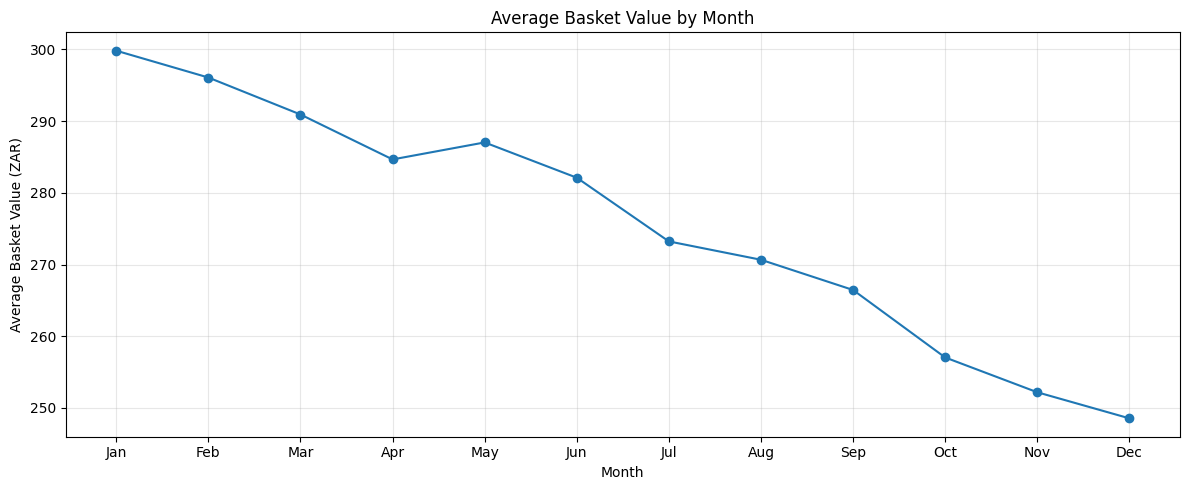

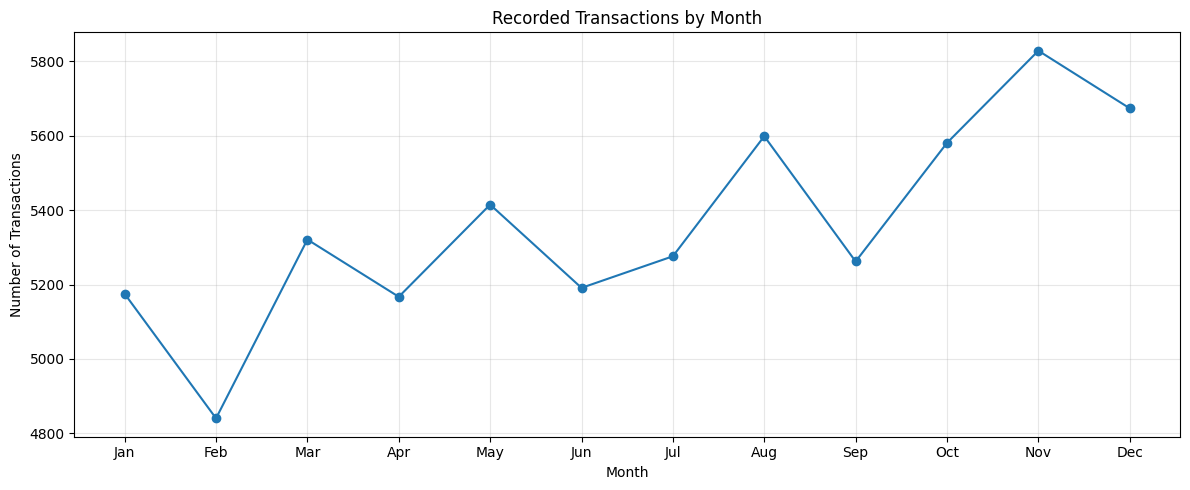

In [0]:
# Plot average basket value over the months
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_summary["month_name"],
    monthly_summary["average_basket_value"],
    marker="o"
)

plt.title("Average Basket Value by Month")
plt.xlabel("Month")
plt.ylabel("Average Basket Value (ZAR)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Plot the number of recorded transactions by month
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_summary["month_name"],
    monthly_summary["transactions"],
    marker="o"
)

plt.title("Recorded Transactions by Month")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [0]:
#Analysis 3 — Compare the first and second halves of the year

# Label transactions as first-half or second-half observations
freshmart["half_year"] = np.where(
    freshmart["month"] <= 6,
    "First half",
    "Second half"
)

# Compare the key basket metrics across the two periods
half_year_summary = freshmart.groupby(
    "half_year",
    as_index=False
).agg(
    transactions=("transaction_id", "nunique"),
    total_revenue=("basket_value_zar", "sum"),
    average_basket_value=("basket_value_zar", "mean"),
    median_basket_value=("basket_value_zar", "median"),
    average_items_per_basket=("num_items", "mean"),
    total_items=("num_items", "sum")
)

display(half_year_summary)

half_year,transactions,total_revenue,average_basket_value,median_basket_value,average_items_per_basket,total_items
First half,31109,9022059.33,290.01444373011026,301.94,14.223568742164646,442481
Second half,33221,8674054.67,261.1015523313567,236.84,12.721892778664097,422634


In [0]:
# For the percentage change, compare the second half with the first half.

# Extract the first-half and second-half rows
first_half = half_year_summary[
    half_year_summary["half_year"] == "First half"
].iloc[0]

second_half = half_year_summary[
    half_year_summary["half_year"] == "Second half"
].iloc[0]

# Calculate the percentage change for each key metric
comparison_metrics = [
    "transactions",
    "total_revenue",
    "average_basket_value",
    "average_items_per_basket"
]

for metric in comparison_metrics:
    first_value = first_half[metric]
    second_value = second_half[metric]

    # Guard against division by zero
    if first_value != 0:
        pct_change = (second_value - first_value) / first_value * 100
        print(f"{metric}: {pct_change:.2f}% change")
    else:
        print(f"{metric}: percentage change cannot be calculated")

transactions: 6.79% change
total_revenue: -3.86% change
average_basket_value: -9.97% change
average_items_per_basket: -10.56% change


#Now we segment the results to investigate root causes

In [0]:
#Analysis 4 — Which stores, formats and provinces are performing differently?

# Compare store formats and provinces using both totals and averages.
# This allows us to compare performance without relying only on total revenue.

store_segment_summary = freshmart.groupby(
    ["province", "store_format"],
    as_index=False,
    observed=True
).agg(
    # Count the number of distinct stores in each segment
    number_of_stores=("store_id", "nunique"),

    # Count recorded shopping trips
    transactions=("transaction_id", "nunique"),

    # Add the recorded basket values
    total_revenue=("basket_value_zar", "sum"),

    # Calculate average spending per transaction
    average_basket_value=("basket_value_zar", "mean"),

    # Calculate the median basket value
    median_basket_value=("basket_value_zar", "median"),

    # Calculate the average items per basket
    average_items_per_basket=("num_items", "mean")
)

# Sort by average basket value to identify segments with lower averages
store_segment_summary = store_segment_summary.sort_values(
    "average_basket_value"
)

display(store_segment_summary)

province,store_format,number_of_stores,transactions,total_revenue,average_basket_value,median_basket_value,average_items_per_basket
KwaZulu-Natal,Express,5,4008,1075965.46,268.4544560878243,261.58,13.100548902195609
Western Cape,Medium,6,8230,2247980.31,273.1446306196841,272.445,13.378979343863913
Gauteng,Large,9,20170,5516629.89,273.50668765493305,269.25,13.356222112047595
Western Cape,Express,2,1732,473768.01,273.53811200923786,265.78499999999997,13.335450346420323
Gauteng,Medium,6,8214,2253129.23,274.3035342098856,272.23,13.38836133430728
Western Cape,Large,5,11271,3109026.35,275.842990861503,274.73,13.54680152604028
Gauteng,Express,3,2375,666078.04,280.4539115789474,286.68,13.624842105263157
KwaZulu-Natal,Medium,6,8330,2353536.71,282.53742016806723,288.565,13.804321728691477


Next, I want to rank individual stores properly.

In [0]:
# Rank stores using average basket value rather than store_id.
# Include transaction counts so that you can see the sample size behind each result.

store_performance = freshmart.groupby(
    ["store_id", "store_name", "province", "store_format"],
    as_index=False,
    observed=True
).agg(
    transactions=("transaction_id", "nunique"),
    total_revenue=("basket_value_zar", "sum"),
    average_basket_value=("basket_value_zar", "mean"),
    median_basket_value=("basket_value_zar", "median"),
    average_items_per_basket=("num_items", "mean")
)

# Sort from highest to lowest average basket value
store_performance = store_performance.sort_values(
    "average_basket_value",
    ascending=False
)

display(store_performance)

store_id,store_name,province,store_format,transactions,total_revenue,average_basket_value,median_basket_value,average_items_per_basket
ST1002,FreshMart Pretoria 3,Gauteng,Express,818,238986.73,292.1598166259169,300.86,14.073349633251834
ST1032,FreshMart Richards Bay 8,KwaZulu-Natal,Medium,1439,417738.74,290.2979430159833,304.51,14.138290479499652
ST1013,FreshMart Randburg 2,Gauteng,Large,2257,643120.68,284.9449180327869,287.15,13.94151528577758
ST1036,FreshMart Pietermaritzburg 2,KwaZulu-Natal,Medium,1430,406390.73,284.1893216783217,292.51,13.832867132867133
ST1026,FreshMart Bellville 7,Western Cape,Medium,1369,387866.71,283.3211906501096,298.03,13.829072315558802
ST1040,FreshMart Pietermaritzburg 5,KwaZulu-Natal,Medium,1391,393234.81,282.69936017253775,285.91,13.79726815240834
ST1041,FreshMart Pietermaritzburg 8,KwaZulu-Natal,Medium,1369,385477.14,281.5757048940833,286.0,13.712198685171659
ST1016,FreshMart Sandton 2,Gauteng,Large,2179,612935.02,281.291886186324,285.46,13.84304726938963
ST1030,FreshMart Cape Town 5,Western Cape,Large,2269,637556.04,280.9854737769943,281.57,13.723666813574262
ST1007,FreshMart Pretoria 8,Gauteng,Large,2229,625236.05,280.50069537909377,281.26,13.659488559892328


In [0]:
#Analysis 5 — Loyalty versus non-loyalty shoppers

# Compare loyalty groups by month.
# This helps establish whether one group is driving a decline over time.

loyalty_monthly = freshmart.groupby(
    ["month", "is_loyalty_member"],
    as_index=False,
    observed=True
).agg(
    transactions=("transaction_id", "nunique"),
    total_revenue=("basket_value_zar", "sum"),
    average_basket_value=("basket_value_zar", "mean"),
    average_items_per_basket=("num_items", "mean")
)

display(loyalty_monthly)

month,is_loyalty_member,transactions,total_revenue,average_basket_value,average_items_per_basket
1,No,2791,803059.5,287.7318165532067,14.10283052669294
1,Yes,2384,748485.31,313.9619588926175,15.510486577181208
2,No,2669,761727.93,285.39825028100415,13.959910078681155
2,Yes,2171,671273.55,309.2001612160295,15.257945647167205
3,No,2919,819350.62,280.6956560465913,13.644398766700926
3,Yes,2402,728643.84,303.348809325562,15.01082431307244
4,No,2891,787824.21,272.50923901764094,13.329989622967831
4,Yes,2276,683008.48,300.0915992970123,14.710456942003514
5,No,2927,799997.0,273.31636487871543,13.361462248035531
5,Yes,2488,754259.58,303.15899517684886,14.82355305466238


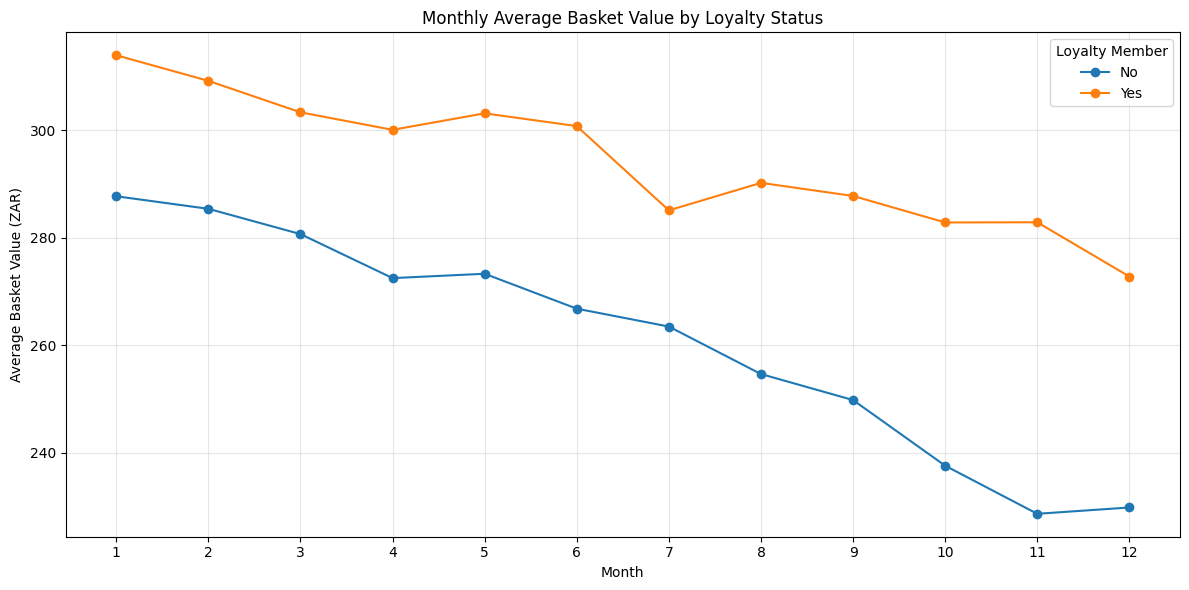

In [0]:
# Plot average basket value for loyalty and non-loyalty transactions

plt.figure(figsize=(12, 6))

for loyalty_status, group in loyalty_monthly.groupby(
    "is_loyalty_member"
):
    group = group.sort_values("month")

    plt.plot(
        group["month"],
        group["average_basket_value"],
        marker="o",
        label=str(loyalty_status)
    )

plt.title("Monthly Average Basket Value by Loyalty Status")
plt.xlabel("Month")
plt.ylabel("Average Basket Value (ZAR)")
plt.xticks(range(1, 13))
plt.legend(title="Loyalty Member")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [0]:
#Analysis 6 — Are smaller baskets becoming more common?
#This analysis examines the distribution and mix of trips rather than just the average.

# Calculate the number and percentage of baskets in each spending band.
# The percentage denominator is the total number of transactions in the sample.

basket_mix = freshmart.groupby(
    "basket_value_band",
    observed=False
).agg(
    transaction_count=("transaction_id", "nunique")
).reset_index()

# Calculate each band's share of all recorded transactions
basket_mix["transaction_share_pct"] = (
    basket_mix["transaction_count"]
    / basket_mix["transaction_count"].sum()
    * 100
)

display(basket_mix)

basket_value_band,transaction_count,transaction_share_pct
Under R100,16562,25.74537540805223
R100–R300,17848,27.744442717239238
R300–R600,27177,42.24623037463081
Over R600,2743,4.263951500077725


To see how that mix changes over time:

In [0]:
# Count baskets in each spending band for every month
monthly_basket_mix = freshmart.groupby(
    ["month", "basket_value_band"],
    observed=False
).agg(
    transaction_count=("transaction_id", "nunique")
).reset_index()

# Calculate the monthly percentage share for each basket band
monthly_basket_mix["monthly_share_pct"] = (
    monthly_basket_mix["transaction_count"]
    / monthly_basket_mix.groupby("month")["transaction_count"]
        .transform("sum")
    * 100
)

display(monthly_basket_mix)

month,basket_value_band,transaction_count,monthly_share_pct
1,Under R100,1108,21.41062801932367
1,R100–R300,1324,25.58454106280193
1,R300–R600,2476,47.84541062801932
1,Over R600,267,5.159420289855072
2,Under R100,1068,22.066115702479337
2,R100–R300,1242,25.66115702479339
2,R300–R600,2285,47.210743801652896
2,Over R600,245,5.06198347107438
3,Under R100,1227,23.059575267806803
3,R100–R300,1429,26.855854162751363


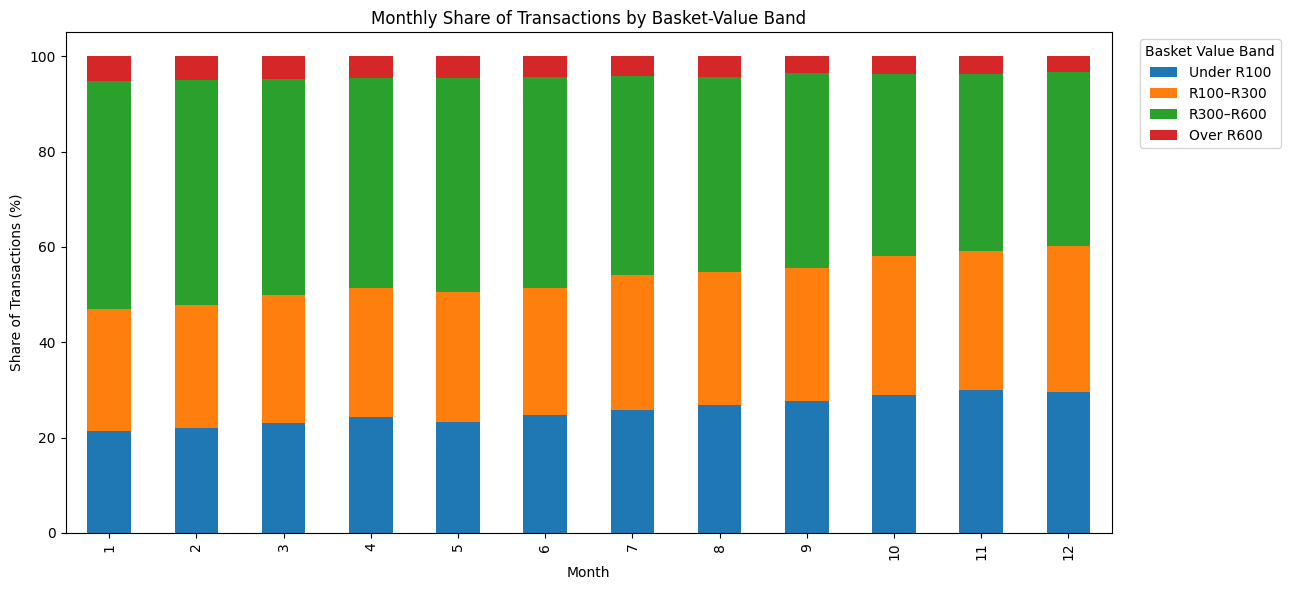

In [0]:
# Visualise the percentage mix of basket-value bands over time

basket_mix_pivot = monthly_basket_mix.pivot(
    index="month",
    columns="basket_value_band",
    values="monthly_share_pct"
)

basket_mix_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("Monthly Share of Transactions by Basket-Value Band")
plt.xlabel("Month")
plt.ylabel("Share of Transactions (%)")
plt.legend(title="Basket Value Band", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

#Hypothesis Testing

#Test 1: Competitor hypothesis
One of the assignment's central hypotheses is that nearby discount competitors may be attracting customers or reducing their spending at FreshMart.

We have 12 stores flagged as having nearby competitors, but a simple comparison of those 12 stores with the other 30 would not be enough. The stores might have had different basket values before the competitor opened.

A stronger approach is to compare the same stores before and after the recorded opening date.

In [0]:
#Compare average baskets before and after opening

# Keep only transactions from stores with a recorded competitor opening date.
# Stores without a date cannot be included in a before/after comparison.

competitor_transactions = freshmart[
    freshmart["competitor_open_date"].notna()
].copy()

# Summarise the transaction metrics before and after the competitor opened
competitor_comparison = competitor_transactions.groupby(
    ["store_id", "competitor_period"],
    as_index=False,
    observed=True
).agg(
    transactions=("transaction_id", "nunique"),
    total_revenue=("basket_value_zar", "sum"),
    average_basket_value=("basket_value_zar", "mean"),
    average_items_per_basket=("num_items", "mean")
)

display(competitor_comparison)

store_id,competitor_period,transactions,total_revenue,average_basket_value,average_items_per_basket
ST1004,Before competitor opening,1645,470373.28,285.94120364741644,14.025531914893618
ST1004,On/after competitor opening,625,134000.1,214.40016,10.3392
ST1008,Before competitor opening,808,237030.27,293.3542945544554,14.292079207920793
ST1008,On/after competitor opening,583,130236.7,223.39056603773585,10.692967409948542
ST1011,Before competitor opening,1368,389644.43,284.8277997076023,13.917397660818713
ST1011,On/after competitor opening,883,194710.31,220.50997734994337,10.5039637599094
ST1012,Before competitor opening,1522,430433.98,282.80813403416556,13.92904073587385
ST1012,On/after competitor opening,760,172247.67,226.6416710526316,10.81578947368421
ST1015,Before competitor opening,1740,494119.02,283.9764482758621,13.891954022988505
ST1015,On/after competitor opening,487,109399.89,224.64043121149896,10.979466119096509


In [0]:
#Calculate the before/after change for each store

# Reshape the results so that each store has separate columns for
# its before-opening and after-opening metrics.

competitor_pivot = competitor_comparison.pivot(
    index="store_id",
    columns="competitor_period",
    values=[
        "transactions",
        "average_basket_value",
        "average_items_per_basket"
    ]
)

display(competitor_pivot)

"('transactions', 'Before competitor opening')","('transactions', 'On/after competitor opening')","('average_basket_value', 'Before competitor opening')","('average_basket_value', 'On/after competitor opening')","('average_items_per_basket', 'Before competitor opening')","('average_items_per_basket', 'On/after competitor opening')"
1645,625,285.94120364741644,214.40016,14.025531914893618,10.3392
808,583,293.3542945544554,223.39056603773585,14.292079207920793,10.692967409948542
1368,883,284.8277997076023,220.50997734994337,13.917397660818713,10.5039637599094
1522,760,282.80813403416556,226.6416710526316,13.92904073587385,10.81578947368421
1740,487,283.9764482758621,224.64043121149896,13.891954022988505,10.979466119096509
1023,304,275.16987292277616,236.98888157894734,13.452590420332356,11.161184210526315
1755,522,293.3651396011396,223.56241379310345,14.341310541310541,10.601532567049809
866,462,280.62539260969976,237.5024025974026,13.823325635103926,11.36147186147186
860,544,289.46256976744183,248.745625,14.206976744186047,11.996323529411764
1729,517,285.4545922498554,211.87245647969053,14.097165991902834,10.28046421663443


To calculate the change in average basket value:

In [0]:
# Select the before and after average basket value columns
before_col = (
    "average_basket_value",
    "Before competitor opening"
)

after_col = (
    "average_basket_value",
    "On/after competitor opening"
)

# Calculate the absolute and percentage change for each store
if before_col in competitor_pivot.columns and after_col in competitor_pivot.columns:

    competitor_pivot["basket_value_change_zar"] = (
        competitor_pivot[after_col] - competitor_pivot[before_col]
    )

    competitor_pivot["basket_value_change_pct"] = (
        competitor_pivot["basket_value_change_zar"]
        / competitor_pivot[before_col]
        * 100
    )

    display(
        competitor_pivot[
            [
                "basket_value_change_zar",
                "basket_value_change_pct"
            ]
        ].sort_values("basket_value_change_pct")
    )
else:
    print(
        "At least one before/after period is missing. "
        "Inspect the competitor comparison table before calculating changes."
    )

"('basket_value_change_zar', '')","('basket_value_change_pct', '')"
-73.58213577016488,-25.77717709503836
-71.54104364741644,-25.019494474686155
-69.96372851671956,-23.849566826004718
-69.80272580803617,-23.793803825137587
-66.378536673838,-23.59541469148862
-65.6567545351474,-22.72849415731664
-64.31782235765894,-22.581300850438808
-59.33601706436312,-20.894696523115385
-56.166462981533954,-19.860271407451307
-43.12299001229715,-15.36674554332779


A decline after opening is consistent with the competition hypothesis, but it does not prove that competition caused the decline. Other changes could have happened at the same time.

#Test 2: stockout hypothesis

The stockout data contains a single recorded category and a common operational note, so we will test whether basket metrics differ on store-days with recorded stockouts.

In [0]:
#Compare affected and unaffected store-days

# Compare basket metrics for transactions with and without a matched
# stockout record on the same store-day.

stockout_comparison = freshmart.groupby(
    "has_recorded_stockout",
    as_index=False
).agg(
    transactions=("transaction_id", "nunique"),
    total_revenue=("basket_value_zar", "sum"),
    average_basket_value=("basket_value_zar", "mean"),
    median_basket_value=("basket_value_zar", "median"),
    average_items_per_basket=("num_items", "mean")
)

# Rename the indicator values to make the results easier to read
stockout_comparison["stockout_group"] = (
    stockout_comparison["has_recorded_stockout"]
    .map({
        True: "Recorded stockout",
        False: "No recorded stockout"
    })
)

display(stockout_comparison)

has_recorded_stockout,transactions,total_revenue,average_basket_value,median_basket_value,average_items_per_basket,stockout_group
false,63724,1.755537402E7,275.4907730211537,274.175,13.468473416609127,No recorded stockout
true,606,140739.98,232.24419141914194,203.54500000000002,11.303630363036303,Recorded stockout


In [0]:
#Compare the difference in average basket value

# Calculate the mean basket value for each group
affected_mean = freshmart.loc[
    freshmart["has_recorded_stockout"],
    "basket_value_zar"
].mean()

unaffected_mean = freshmart.loc[
    ~freshmart["has_recorded_stockout"],
    "basket_value_zar"
].mean()

# Calculate the absolute difference
difference_zar = affected_mean - unaffected_mean

print(f"Average basket value on recorded stockout days: R{affected_mean:.2f}")
print(f"Average basket value on other store-days: R{unaffected_mean:.2f}")
print(f"Difference in average basket value: R{difference_zar:.2f}")

Average basket value on recorded stockout days: R232.24
Average basket value on other store-days: R275.49
Difference in average basket value: R-43.25


In [0]:
#Compare stockout and non-stockout days within weekdays and weekend

# Compare the stockout association separately for weekdays and weekends.
# This helps account for differences in typical shopping patterns.

stockout_daytype_comparison = freshmart.groupby(
    ["day_type", "has_recorded_stockout"],
    as_index=False
).agg(
    transactions=("transaction_id", "nunique"),
    average_basket_value=("basket_value_zar", "mean"),
    average_items_per_basket=("num_items", "mean")
)

display(stockout_daytype_comparison)

day_type,has_recorded_stockout,transactions,average_basket_value,average_items_per_basket
Weekday,false,40831,274.77367882246335,13.435551419264774
Weekend,false,22893,276.76975232603854,13.5271917179924
Weekend,true,606,232.24419141914194,11.303630363036303


#Investigate weekday and payment patterns

In [0]:
#Weekday and weekend comparisons

# Compare shopping behaviour on weekdays and weekends
daytype_summary = freshmart.groupby(
    "day_type",
    as_index=False
).agg(
    transactions=("transaction_id", "nunique"),
    total_revenue=("basket_value_zar", "sum"),
    average_basket_value=("basket_value_zar", "mean"),
    median_basket_value=("basket_value_zar", "median"),
    average_items_per_basket=("num_items", "mean")
)

display(daytype_summary)

day_type,transactions,total_revenue,average_basket_value,median_basket_value,average_items_per_basket
Weekday,40831,1.121928408E7,274.77367882246335,273.17,13.435551419264774
Weekend,23499,6476829.92,275.6215124047832,273.8,13.469849780841738


# Payment method

In [0]:
# Compare basket metrics by payment method.


# This tests whether different payment groups have different spending patterns.

payment_summary = freshmart.groupby(
    "payment_method",
    as_index=False,
    observed=True
).agg(
    transactions=("transaction_id", "nunique"),
    total_revenue=("basket_value_zar", "sum"),
    average_basket_value=("basket_value_zar", "mean"),
    average_items_per_basket=("num_items", "mean")
)

display(payment_summary)

payment_method,transactions,total_revenue,average_basket_value,average_items_per_basket
Card,32306,8878290.11,274.8186129511546,13.426546152417508
Cash,19754,5456518.24,276.2234605649489,13.515794269515036
Mobile,12270,3361305.65,273.94504074979625,13.395762021189894


Be careful not to interpret these differences as causal. For example, cash transactions may have lower average values, but that does not mean cash payment causes customers to spend less.

#Calculate the size of the decline

In [0]:
# Define a reusable function to calculate percentage change.
# The function compares a new value with an earlier value.

def calculate_percentage_change(old_value, new_value):

    # Avoid division by zero
    if pd.isna(old_value) or old_value == 0:
        return np.nan

    # Return the percentage change
    return ((new_value - old_value) / old_value) * 100


# Example: compare the first half with the second half of the year
first_half_basket = first_half["average_basket_value"]
second_half_basket = second_half["average_basket_value"]

basket_change_pct = calculate_percentage_change(
    first_half_basket,
    second_half_basket
)

print(f"First-half average basket: R{first_half_basket:.2f}")
print(f"Second-half average basket: R{second_half_basket:.2f}")
print(f"Percentage change: {basket_change_pct:.2f}%")

First-half average basket: R290.01
Second-half average basket: R261.10
Percentage change: -9.97%


#Evaluate the hypotheses

#Test H1: Are customers spending less per visit?



In [0]:

# Compare the first and second halves of 2025.
# The values come from the summary already created in your notebook.

display(
    half_year_summary[
        [
            "half_year",
            "transactions",
            "total_revenue",
            "average_basket_value",
            "average_items_per_basket"
        ]
    ].round(2)
)

# Print the key percentage changes for a business audience.
print("H1 vs H2: key findings")
print("Recorded transactions increased by 6.79%.")
print("Recorded basket value decreased by 3.86%.")
print("Average basket value decreased by 9.97%.")
print("Average items per basket decreased by 10.56%.")


half_year,transactions,total_revenue,average_basket_value,average_items_per_basket
First half,31109,9022059.33,290.01,14.22
Second half,33221,8674054.67,261.1,12.72


H1 vs H2: key findings
Recorded transactions increased by 6.79%.
Recorded basket value decreased by 3.86%.
Average basket value decreased by 9.97%.
Average items per basket decreased by 10.56%.


Important findings.

What it means: The sample contains more recorded transactions in the second half of 2025, but total recorded basket value is lower. Average basket value and average items per basket also declined.

That pattern is consistent with shoppers making smaller purchases. However, that these are recorded transactions from a sample, not confirmed chain-wide footfall or total turnover.

# Test H2: Are nearby competitors affecting performance?

In [0]:

# Recalculate the before-and-after comparison at store level.
# This keeps the comparison focused on the same stores.

competitor_check = freshmart[
    freshmart["competitor_open_date"].notna()
].groupby(
    ["store_id", "competitor_period"],
    observed=True
).agg(
    transactions=("transaction_id", "nunique"),
    average_basket_value=("basket_value_zar", "mean"),
    average_items_per_basket=("num_items", "mean")
).reset_index()

# Put the before and after results side by side.
competitor_basket = competitor_check.pivot(
    index="store_id",
    columns="competitor_period",
    values="average_basket_value"
)

before = "Before competitor opening"
after = "On/after competitor opening"

# Confirm that both periods are available.
if before in competitor_basket.columns and after in competitor_basket.columns:

    # Calculate the change for each store.
    competitor_basket["change_zar"] = (
        competitor_basket[after] - competitor_basket[before]
    )

    competitor_basket["change_pct"] = (
        competitor_basket["change_zar"]
        / competitor_basket[before].replace(0, np.nan)
        * 100
    )

    # Keep only stores with data for both periods.
    valid_changes = competitor_basket.dropna(
        subset=[before, after]
    ).copy()

    display(
        valid_changes[
            [before, after, "change_zar", "change_pct"]
        ].sort_values("change_pct")
    )

    print("Stores with comparable before-and-after data:",
          len(valid_changes))

    print("Stores where average basket value declined:",
          (valid_changes["change_zar"] < 0).sum())

    print("Stores where average basket value increased:",
          (valid_changes["change_zar"] > 0).sum())

    print("Average percentage change across comparable stores:",
          round(valid_changes["change_pct"].mean(), 2), "%")

else:
    print("Both before and after periods are not available.")
    print("Review competitor_check and the competitor opening dates.")


Before competitor opening,On/after competitor opening,change_zar,change_pct
285.4545922498554,211.87245647969053,-73.58213577016488,-25.77717709503836
285.94120364741644,214.40016,-71.54104364741644,-25.019494474686155
293.3542945544554,223.39056603773585,-69.96372851671956,-23.849566826004718
293.3651396011396,223.56241379310345,-69.80272580803617,-23.793803825137587
281.3196442687747,214.9411075949367,-66.378536673838,-23.59541469148862
288.87419501133786,223.21744047619046,-65.6567545351474,-22.72849415731664
284.8277997076023,220.50997734994337,-64.31782235765894,-22.581300850438808
283.9764482758621,224.64043121149896,-59.33601706436312,-20.894696523115385
282.80813403416556,226.6416710526316,-56.166462981533954,-19.860271407451307
280.62539260969976,237.5024025974026,-43.12299001229715,-15.36674554332779


Stores with comparable before-and-after data: 12
Stores where average basket value declined: 12
Stores where average basket value increased: 0
Average percentage change across comparable stores: -20.95 %


How to interpret the results
- If most comparable stores show a decline, the findings are consistent with the competitor hypothesis.
- If most show an increase, the hypothesis is not supported by this comparison.
- If results are mixed, competition may affect some stores differently from others.
Also check how many transactions each store has in each period. A store with very few observations before or after the opening date may produce an unreliable comparison.

Important: This is a before-and-after comparison, not proof that competitors caused the changes. Seasonality, pricing, promotions, and other store changes could also contribute.

#Test H3: Are stockouts associated with lower spending?

In [0]:

# Compare recorded stockout days with other days.
# Separate weekdays and weekends to check whether the pattern differs.

display(
    stockout_daytype_comparison.sort_values(
        ["day_type", "has_recorded_stockout"]
    ).round(2)
)

# Calculate the basket value gap within each day type.
stockout_gap = stockout_daytype_comparison.pivot(
    index="day_type",
    columns="has_recorded_stockout",
    values="average_basket_value"
)

# Continue only if both groups exist in the comparison.
if True in stockout_gap.columns and False in stockout_gap.columns:

    stockout_gap["difference_zar"] = (
        stockout_gap[True] - stockout_gap[False]
    )

    display(stockout_gap.round(2))

    print(
        "A negative difference means the average basket value was "
        "lower on recorded stockout days within that day type."
    )


day_type,has_recorded_stockout,transactions,average_basket_value,average_items_per_basket
Weekday,false,40831,274.77,13.44
Weekend,false,22893,276.77,13.53
Weekend,true,606,232.24,11.3


False,True,difference_zar
274.77,null,null
276.77,232.24,-44.53


A negative difference means the average basket value was lower on recorded stockout days within that day type.


If the stockout-day average is lower for both weekdays and weekends, the association is less likely to be explained solely by a simple weekday-versus-weekend difference. It still does not establish causation.

#Test H4: Do loyalty and shopping patterns help explain the decline?

In [0]:

# Label each transaction as belonging to the first or second half of 2025.
freshmart["half_year"] = np.where(
    freshmart["month"] <= 6,
    "First half",
    "Second half"
)

# Compare loyalty and non-loyalty groups separately.
loyalty_half_year = freshmart.groupby(
    ["is_loyalty_member", "half_year"],
    as_index=False,
    observed=True
).agg(
    transactions=("transaction_id", "nunique"),
    average_basket_value=("basket_value_zar", "mean"),
    average_items_per_basket=("num_items", "mean"),
    total_revenue=("basket_value_zar", "sum")
)

display(loyalty_half_year.round(2))

# Calculate percentage changes for each loyalty group.
loyalty_pivot = loyalty_half_year.pivot(
    index="is_loyalty_member",
    columns="half_year",
    values=[
        "transactions",
        "average_basket_value",
        "average_items_per_basket"
    ]
)

display(loyalty_pivot.round(2))


is_loyalty_member,half_year,transactions,average_basket_value,average_items_per_basket,total_revenue
No,First half,17051,277.61,13.57,4733465.09
No,Second half,18623,243.48,11.82,4534358.71
Yes,First half,14058,305.06,15.01,4288594.24
Yes,Second half,14598,283.58,13.88,4139695.96


"('transactions', 'First half')","('transactions', 'Second half')","('average_basket_value', 'First half')","('average_basket_value', 'Second half')","('average_items_per_basket', 'First half')","('average_items_per_basket', 'Second half')"
17051,18623,277.6063040290892,243.48164688825645,13.572283150548355,11.816248724695269
14058,14598,305.06432209418125,283.5796657076312,15.013515436050648,13.877243458007946


Interpret the results by asking:
- Did average basket value decline for both loyalty groups, or mainly one?
- Did average items per basket also decline?
- Did transaction counts change differently between the groups?
If both groups have declining basket values, the issue may be broader than loyalty participation alone. If one group has a much larger decline, that group deserves closer investigation.

Your existing overall results show that the average loyalty basket is R294.12, compared with R259.79 for non-loyalty transactions. That is a useful descriptive difference, but the half-year comparison above will help you determine whether loyalty patterns changed over time.

# D2. Turn the actions into measurable experiments

Rather than immediately rolling out changes across all 42 stores, management could test selected interventions first.
Suggested pilot plan
1. Establish a baseline. Record current basket value, items per basket and stockout hours for the selected stores.
2. Choose a small pilot group. For example, select stores with recurring weekend stockouts for a replenishment improvement.
3. Compare results over a defined period. Track the same metrics before and after the change and, where possible, compare with similar stores that did not receive the intervention.
4. Decide whether to scale. Expand only if the improvement is meaningful and is not offset by higher costs or lower margins.

For your case study, you do not need to prove that these interventions will work. Your role is to recommend sensible actions that management can test.
D3. Add a simple monitoring framework
These are the KPIs I would recommend FreshMart monitor monthly:
- Average basket value: total recorded basket value divided by transaction count.
- Average items per basket: total items divided by transaction count.
- Transaction count: the number of recorded transactions, clearly distinguished from actual footfall.
- Share of low-value baskets: percentage of transactions below R100 and between R100 and R300.
- Stockout incidents and duration: frequency and hours of recorded stockouts by store.
- Store-level performance: average basket value and items per basket, with transaction counts for context.
A key limitation to state in your recommendations is that the supplied transactions are a sample. Management should validate any trend against complete sales and footfall data before treating it as a chain-wide result.

#Matplotlib dashboard

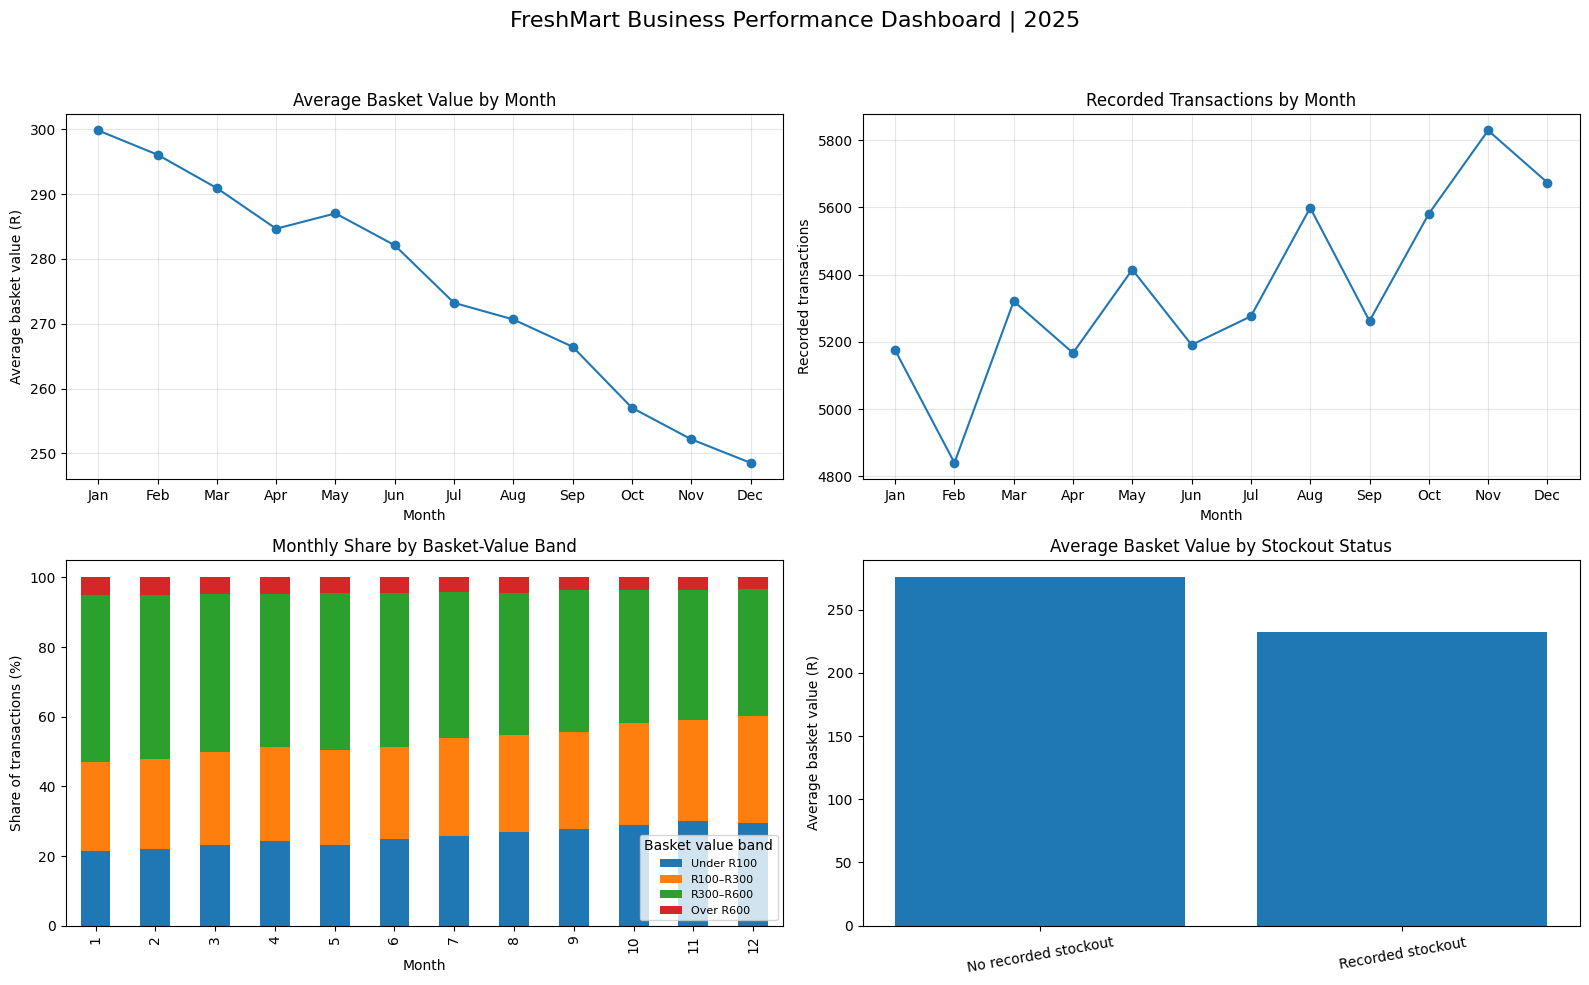

In [0]:

import matplotlib.pyplot as plt
import numpy as np

# Create one figure with four charts.
# Each chart answers a different business question.
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# --------------------------------------------------
# Chart 1: Average basket value by month
# Business question: How did basket spending change?
# --------------------------------------------------

ax = axes[0, 0]

ax.plot(
    monthly_summary["month_name"],
    monthly_summary["average_basket_value"],
    marker="o"
)

ax.set_title("Average Basket Value by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Average basket value (R)")
ax.grid(True, alpha=0.3)


# --------------------------------------------------
# Chart 2: Recorded transactions by month
# Business question: Did recorded shopping trips change?
# --------------------------------------------------

ax = axes[0, 1]

ax.plot(
    monthly_summary["month_name"],
    monthly_summary["transactions"],
    marker="o"
)

ax.set_title("Recorded Transactions by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Recorded transactions")
ax.grid(True, alpha=0.3)


# --------------------------------------------------
# Chart 3: Monthly basket-value mix
# Business question: Are lower-value baskets becoming
# a larger share of transactions?
# --------------------------------------------------

ax = axes[1, 0]

basket_mix_pivot.plot(
    kind="bar",
    stacked=True,
    ax=ax
)

ax.set_title("Monthly Share by Basket-Value Band")
ax.set_xlabel("Month")
ax.set_ylabel("Share of transactions (%)")
ax.legend(
    title="Basket value band",
    fontsize=8
)


# --------------------------------------------------
# Chart 4: Basket value on recorded stockout days
# Business question: Is there an association with
# lower basket spending?
# --------------------------------------------------

ax = axes[1, 1]

stockout_plot = stockout_comparison.copy()

# Use readable labels for the x-axis.
stockout_plot["stockout_group"] = (
    stockout_plot["has_recorded_stockout"]
    .map({
        True: "Recorded stockout",
        False: "No recorded stockout"
    })
)

ax.bar(
    stockout_plot["stockout_group"],
    stockout_plot["average_basket_value"]
)

ax.set_title("Average Basket Value by Stockout Status")
ax.set_xlabel("")
ax.set_ylabel("Average basket value (R)")
ax.tick_params(axis="x", rotation=10)


# Add a dashboard heading and adjust spacing.
fig.suptitle(
    "FreshMart Business Performance Dashboard | 2025",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
